In [1]:
# ================================================================================
# INDIAN STOCK SENTIMENT ANALYSIS & PREDICTION PIPELINE
# ================================================================================
# This notebook demonstrates:
# 1. Fine-tuning FinBERT models on Indian financial news
# 2. Creating comprehensive sentiment and technical features
# 3. Building time-series sequences for stock prediction
# ================================================================================

import os
import pandas as pd
import numpy as np
import yfinance as yf
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Transformers and ML libraries
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification,
    TrainingArguments, 
    Trainer,
    DataCollatorWithPadding
)
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import RobustScaler
from sklearn.impute import KNNImputer

# Technical indicators
import pandas_ta as ta

In [2]:
# Suppress warnings and set environment
import warnings
warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_NO_TF"] = "1"

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:

# ================================================================================
# 1. DATA LOADING AND PREPROCESSING
# ================================================================================

def load_indian_financial_news():
    """Load and preprocess Indian financial news dataset"""
    import kagglehub
    
    # Download dataset
    path = kagglehub.dataset_download("hkapoor/indian-financial-news-articles-20032020")
    csv_path = os.path.join(path, "IndianFinancialNews.csv")
    news_df = pd.read_csv(csv_path, parse_dates=["Date"])
    
    print(f"Loaded {len(news_df)} news articles")
    return news_df

def create_nifty50_mapping():
    """Create mapping for NIFTY 50 companies"""
    return {
        "Adani Enterprises": "ADANIENT.NS",
        "Adani Ports": "ADANIPORTS.NS",
        "Apollo Hospitals": "APOLLOHOSP.NS",
        "Asian Paints": "ASIANPAINT.NS",
        "Axis Bank": "AXISBANK.NS",
        "Bajaj Auto": "BAJAJ-AUTO.NS",
        "Bajaj Finance": "BAJFINANCE.NS",
        "Bajaj Finserv": "BAJAJFINSV.NS",
        "Bharat Electronics": "BEL.NS",
        "Bharti Airtel": "BHARTIARTL.NS",
        "Cipla": "CIPLA.NS",
        "Coal India": "COALINDIA.NS",
        "Dr. Reddy": "DRREDDY.NS",
        "Eicher Motors": "EICHERMOT.NS",
        "Grasim Industries": "GRASIM.NS",
        "HCL Technologies": "HCLTECH.NS",
        "HDFC Bank": "HDFCBANK.NS",
        "HDFC Life": "HDFCLIFE.NS",
        "Hero MotoCorp": "HEROMOTOCO.NS",
        "Hindalco": "HINDALCO.NS",
        "Hindustan Unilever": "HINDUNILVR.NS",
        "ICICI Bank": "ICICIBANK.NS",
        "ITC": "ITC.NS",
        "IndusInd Bank": "INDUSINDBK.NS",
        "Infosys": "INFY.NS",
        "JSW Steel": "JSWSTEEL.NS",
        "Jio Financial": "JIOFIN.NS",
        "Kotak Mahindra Bank": "KOTAKBANK.NS",
        "Larsen & Toubro": "LT.NS",
        "M&M": "M&M.NS",
        "Maruti Suzuki": "MARUTI.NS",
        "NTPC": "NTPC.NS",
        "Nestle India": "NESTLEIND.NS",
        "ONGC": "ONGC.NS",
        "Power Grid": "POWERGRID.NS",
        "Reliance Industries": "RELIANCE.NS",
        "SBI Life": "SBILIFE.NS",
        "Shriram Finance": "SHRIRAMFIN.NS",
        "State Bank of India": "SBIN.NS",
        "Sun Pharma": "SUNPHARMA.NS",
        "TCS": "TCS.NS",
        "Tata Consumer": "TATACONSUM.NS",
        "Tata Motors": "TATAMOTORS.NS",
        "Tata Steel": "TATASTEEL.NS",
        "Tech Mahindra": "TECHM.NS",
        "Titan": "TITAN.NS",
        "Trent": "TRENT.NS",
        "UltraTech Cement": "ULTRACEMCO.NS",
        "Wipro": "WIPRO.NS"
    }

def detect_nifty_stock(title, nifty_50_map):
    """Detect which NIFTY 50 stock is mentioned in news title"""
    for company, ticker in nifty_50_map.items():
        if company.lower() in title.lower():
            return company, ticker
    return None, None

def preprocess_news_data():
    """Main preprocessing pipeline for news data"""
    # Load data
    news_df = load_indian_financial_news()
    nifty_50_map = create_nifty50_mapping()
    
    # Map companies to tickers
    news_df[['Company', 'Ticker']] = news_df['Title'].apply(
        lambda t: pd.Series(detect_nifty_stock(t, nifty_50_map))
    )
    
    # Filter only NIFTY 50 companies
    news_df = news_df.dropna(subset=['Ticker'])
    
    print(f"Filtered to {len(news_df)} articles for NIFTY 50 companies")
    print(f"Date range: {news_df['Date'].min()} to {news_df['Date'].max()}")
    
    return news_df

In [4]:

# ================================================================================
# 2. FINBERT MODEL FINE-TUNING
# ================================================================================

class FinBERTModelManager:
    """Manage different FinBERT model options and training"""
    
    AVAILABLE_MODELS = {
        "finbert-tone": "yiyanghkust/finbert-tone",
        "prosus-finbert": "ProsusAI/finbert",
        "finbert-esg": "yiyanghkust/finbert-esg"
    }
    
    def __init__(self, model_choice="finbert-tone"):
        self.model_name = self.AVAILABLE_MODELS.get(model_choice, model_choice)
        self.tokenizer = None
        self.model = None
        self.trained_model_path = None
    
    def load_base_model(self):
        """Load the base FinBERT model"""
        print(f"Loading base model: {self.model_name}")
        self.tokenizer = AutoTokenizer.from_pretrained(self.model_name)
        self.model = AutoModelForSequenceClassification.from_pretrained(
            self.model_name,
            num_labels=3,
            trust_remote_code=False,
            use_safetensors=True
        ).to(device)
        return self.tokenizer, self.model
    
    def prepare_training_data(self):
        """Load and prepare Indian financial sentiment dataset"""
        print("Loading Indian Financial News sentiment dataset...")
        dataset = load_dataset("kdave/Indian_Financial_News")
        
        # Create label mapping
        label2id = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
        id2label = {v: k for k, v in label2id.items()}
        
        def encode_labels(example):
            example["label"] = label2id[example["Sentiment"]]
            return example
        
        def tokenize(example):
            return self.tokenizer(
                example["Content"],
                padding="max_length",
                truncation=True,
                max_length=512,
            )
        
        # Process dataset
        dataset = dataset.map(encode_labels)
        dataset = dataset.map(tokenize, batched=True)
        dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
        
        return dataset, label2id, id2label
    
    def fine_tune_model(self, output_dir="./finbert-indian-sentiment", 
                       num_epochs=3, batch_size=16):
        """Fine-tune FinBERT on Indian financial news"""
        
        # Prepare data
        dataset, label2id, id2label = self.prepare_training_data()
        
        # Update model configuration
        self.model.config.id2label = id2label
        self.model.config.label2id = label2id
        
        # Training arguments
        training_args = TrainingArguments(
            output_dir=output_dir,
            eval_strategy="epoch",
            save_strategy="epoch",
            learning_rate=2e-5,
            per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=32,
            num_train_epochs=num_epochs,
            weight_decay=0.01,
            logging_dir="./logs",
            logging_steps=10,
            load_best_model_at_end=True,
            metric_for_best_model="f1"
        )
        
        # Metrics function
        def compute_metrics(eval_pred):
            logits, labels = eval_pred
            predictions = logits.argmax(axis=-1)
            return {
                'accuracy': accuracy_score(labels, predictions),
                'f1': f1_score(labels, predictions, average='weighted'),
            }
        
        # Data collator
        data_collator = DataCollatorWithPadding(
            tokenizer=self.tokenizer, 
            return_tensors="pt"
        )
        
        # Create trainer
        trainer = Trainer(
            model=self.model,
            args=training_args,
            train_dataset=dataset["train"].train_test_split(test_size=0.2)["train"],
            eval_dataset=dataset["train"].train_test_split(test_size=0.2)["test"],
            tokenizer=self.tokenizer,
            data_collator=data_collator,
            compute_metrics=compute_metrics
        )
        
        # Train model
        print("Starting fine-tuning...")
        trainer.train()
        
        # Save model
        trainer.save_model(output_dir)
        self.tokenizer.save_pretrained(output_dir)
        self.trained_model_path = output_dir
        
        print(f"Model saved to: {output_dir}")
        return trainer
    
    def load_trained_model(self, model_path):
        """Load a fine-tuned model"""
        print(f"Loading trained model from: {model_path}")
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
        self.model.eval()
        self.trained_model_path = model_path
        return self.tokenizer, self.model
    
    def get_sentiment(self, text):
        """Get sentiment scores for text"""
        if self.tokenizer is None or self.model is None:
            raise ValueError("Model not loaded. Call load_base_model() or load_trained_model() first.")
        
        inputs = self.tokenizer(
            text,
            truncation=True,
            max_length=128,
            padding=True,
            return_tensors='pt'
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            scores = torch.nn.functional.softmax(outputs.logits, dim=1).detach().cpu().numpy()[0]
        
        # Get label order from model config
        id2label = self.model.config.id2label
        label_order = [id2label[i] for i in range(len(id2label))]
        
        return {label: float(scores[i] * 100) for i, label in enumerate(label_order)}

In [5]:
# ================================================================================
# 3. SENTIMENT ANALYSIS AND FEATURE ENGINEERING
# ================================================================================

def analyze_sentiment_with_model(news_df, model_manager):
    """Apply sentiment analysis to news data"""
    print("Analyzing sentiment for all news articles...")
    
    # Apply sentiment analysis
    news_df["sentiment"] = news_df["Title"].apply(model_manager.get_sentiment)
    
    # Extract dominant sentiment label
    def extract_sentiment_label(sent_dict):
        return max(sent_dict, key=sent_dict.get) if isinstance(sent_dict, dict) else "unknown"
    
    news_df["sentiment_label"] = news_df["sentiment"].apply(extract_sentiment_label)
    
    return news_df

def create_sentiment_visualizations(news_df):
    """Create comprehensive sentiment analysis visualizations"""
    
    # 1. Articles per stock
    plt.figure(figsize=(15, 6))
    stock_counts = news_df['Ticker'].value_counts()
    sns.barplot(x=stock_counts.index, y=stock_counts.values, palette="Blues_d")
    plt.title('Number of News Articles per Stock', fontsize=14, fontweight='bold')
    plt.xlabel('Stock Ticker')
    plt.ylabel('News Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    # 2. Sentiment distribution per stock
    plt.figure(figsize=(15, 8))
    sentiment_dist = news_df.groupby(['Ticker', 'sentiment_label']).size().unstack(fill_value=0)
    sentiment_dist.plot(kind='bar', stacked=True, colormap='RdYlGn', ax=plt.gca())
    plt.title('Sentiment Distribution per Stock', fontsize=14, fontweight='bold')
    plt.xlabel('Stock Ticker')
    plt.ylabel('Number of Articles')
    plt.xticks(rotation=45)
    plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    
    # 3. Overall sentiment distribution
    plt.figure(figsize=(10, 6))
    sentiment_counts = news_df['sentiment_label'].value_counts()
    colors = ['#ff6b6b', '#ffd93d', '#6bcf7f']  # Red, Yellow, Green
    plt.pie(sentiment_counts.values, labels=sentiment_counts.index, 
            autopct='%1.1f%%', colors=colors, startangle=90)
    plt.title('Overall Sentiment Distribution', fontsize=14, fontweight='bold')
    plt.show()

def align_sentiment_stock_data(news_df, stock_data):
    """Align news sentiment data with stock prices by date"""
    
    # Ensure proper date formats
    news_df['Date'] = pd.to_datetime(news_df['Date']).dt.date
    stock_data['Date'] = pd.to_datetime(stock_data['Date']).dt.date
    
    # Aggregate multiple news sentiment scores per day
    daily_sentiment = news_df.groupby(['Date', 'Ticker']).agg({
        'sentiment': lambda x: {
            'avg_positive': sum([s.get('positive', s.get('Positive', 0)) for s in x]) / len(x),
            'avg_neutral': sum([s.get('neutral', s.get('Neutral', 0)) for s in x]) / len(x),
            'avg_negative': sum([s.get('negative', s.get('Negative', 0)) for s in x]) / len(x),
            'news_count': len(x),
            'sentiment_std': np.std([s.get('positive', s.get('Positive', 0)) - 
                                   s.get('negative', s.get('Negative', 0)) for s in x])
        }
    }).reset_index()
    
    # Expand sentiment dictionary into columns
    sentiment_expanded = pd.json_normalize(daily_sentiment['sentiment'])
    daily_sentiment = pd.concat([daily_sentiment[['Date', 'Ticker']], 
                               sentiment_expanded], axis=1)
    
    # Merge with stock data
    merged_df = stock_data.merge(daily_sentiment, 
                                on=['Date', 'Ticker'], 
                                how='left')
    
    # Handle days with no news using forward fill
    sentiment_cols = ['avg_positive', 'avg_neutral', 'avg_negative', 
                     'news_count', 'sentiment_std']
    merged_df[sentiment_cols] = merged_df.groupby('Ticker')[sentiment_cols].fillna(method='ffill')
    
    # Fill remaining NaN with neutral sentiment
    merged_df['avg_positive'].fillna(33.33, inplace=True)
    merged_df['avg_neutral'].fillna(33.33, inplace=True)
    merged_df['avg_negative'].fillna(33.33, inplace=True)
    merged_df['news_count'].fillna(0, inplace=True)
    merged_df['sentiment_std'].fillna(0, inplace=True)
    
    return merged_df

In [13]:
# ================================================================================
# 4. TECHNICAL INDICATORS AND FEATURE ENGINEERING
# ================================================================================
# def create_comprehensive_features(df, price_col='Close'):
#     """Create comprehensive technical and sentiment features"""
    
#     df = df.copy()
    
#     # Ensure Date column is datetime and set as index for technical indicators
#     if 'Date' in df.columns:
#         df['Date'] = pd.to_datetime(df['Date'])
#         df = df.sort_values('Date')
#         df = df.set_index('Date')
    
#     # Technical indicators
#     df['SMA_5'] = ta.sma(df[price_col], length=5)
#     df['SMA_10'] = ta.sma(df[price_col], length=10)
#     df['SMA_20'] = ta.sma(df[price_col], length=20)
#     df['EMA_12'] = ta.ema(df[price_col], length=12)
#     df['EMA_26'] = ta.ema(df[price_col], length=26)
    
#     # Momentum indicators
#     df['RSI'] = ta.rsi(df[price_col], length=14)
#     macd_data = ta.macd(df[price_col])
#     df['MACD'] = macd_data['MACD_12_26_9']
#     df['MACD_signal'] = macd_data['MACDs_12_26_9']
#     df['MACD_hist'] = macd_data['MACDh_12_26_9']
    
#     # Bollinger Bands
#     bb = ta.bbands(df[price_col], length=20)
#     df['BB_upper'] = bb['BBU_20_2.0']
#     df['BB_middle'] = bb['BBM_20_2.0']
#     df['BB_lower'] = bb['BBL_20_2.0']
    
#     # Volume indicators
#     df['OBV'] = ta.obv(df[price_col], df['Volume'])
    
#     # VWAP - Fixed version with proper error handling
#     try:
#         # Ensure we have a proper DatetimeIndex
#         if isinstance(df.index, pd.DatetimeIndex):
#             df['VWAP'] = ta.vwap(df['High'], df['Low'], df[price_col], df['Volume'])
#         else:
#             # Fallback: Calculate simple VWAP manually
#             typical_price = (df['High'] + df['Low'] + df[price_col]) / 3
#             df['VWAP'] = (typical_price * df['Volume']).cumsum() / df['Volume'].cumsum()
#     except Exception as e:
#         print(f"VWAP calculation failed, using fallback method: {e}")
#         # Manual VWAP calculation
#         typical_price = (df['High'] + df['Low'] + df[price_col]) / 3
#         df['VWAP'] = (typical_price * df['Volume']).cumsum() / df['Volume'].cumsum()
    
#     # Price features
#     df['Returns'] = df[price_col].pct_change()
#     df['Log_Returns'] = np.log(df[price_col] / df[price_col].shift(1))
#     df['High_Low_Ratio'] = df['High'] / df['Low']
    
#     # Advanced sentiment features (if sentiment columns exist)
#     if 'avg_positive' in df.columns:
#         df['Sentiment_Trend_3d'] = (df['avg_positive'].rolling(3).mean() - 
#                                    df['avg_negative'].rolling(3).mean())
#         df['Sentiment_Trend_7d'] = (df['avg_positive'].rolling(7).mean() - 
#                                    df['avg_negative'].rolling(7).mean())
#         df['Sentiment_Volatility'] = ((df['avg_positive'] - df['avg_negative'])
#                                      .rolling(5).std())
#         df['News_Volume_MA'] = df['news_count'].rolling(5).mean()
#         df['News_Volume_Spike'] = (df['news_count'] > df['News_Volume_MA'] * 1.5).astype(int)
#         df['Extreme_Positive'] = (df['avg_positive'] > 70).astype(int)
#         df['Extreme_Negative'] = (df['avg_negative'] > 70).astype(int)
    
#     # Reset index to get Date back as a column
#     df = df.reset_index()
    
#     return df
def create_comprehensive_features(df, price_col='Close'):
    """Fixed version that handles NaN values in technical indicators"""
    
    df = df.copy()
    
    # Ensure Date column is datetime and set as index
    if 'Date' in df.columns:
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.sort_values('Date')
        df = df.set_index('Date')
    
    # Technical indicators
    df['SMA_5'] = ta.sma(df[price_col], length=5)
    df['SMA_10'] = ta.sma(df[price_col], length=10)
    df['SMA_20'] = ta.sma(df[price_col], length=20)
    df['EMA_12'] = ta.ema(df[price_col], length=12)
    df['EMA_26'] = ta.ema(df[price_col], length=26)
    
    # Momentum indicators
    df['RSI'] = ta.rsi(df[price_col], length=14)
    macd_data = ta.macd(df[price_col])
    df['MACD'] = macd_data['MACD_12_26_9'] if macd_data is not None else np.nan
    df['MACD_signal'] = macd_data['MACDs_12_26_9'] if macd_data is not None else np.nan
    df['MACD_hist'] = macd_data['MACDh_12_26_9'] if macd_data is not None else np.nan
    
    # Bollinger Bands
    bb = ta.bbands(df[price_col], length=20)
    df['BB_upper'] = bb['BBU_20_2.0'] if bb is not None else np.nan
    df['BB_middle'] = bb['BBM_20_2.0'] if bb is not None else np.nan
    df['BB_lower'] = bb['BBL_20_2.0'] if bb is not None else np.nan
    
    # Volume indicators
    df['OBV'] = ta.obv(df[price_col], df['Volume'])
    
    # Manual VWAP calculation (more reliable)
    typical_price = (df['High'] + df['Low'] + df[price_col]) / 3
    df['VWAP'] = (typical_price * df['Volume']).cumsum() / df['Volume'].cumsum()
    
    # Price features
    df['Returns'] = df[price_col].pct_change()
    df['Log_Returns'] = np.log(df[price_col] / df[price_col].shift(1))
    df['High_Low_Ratio'] = df['High'] / df['Low']
    
    # **🔧 KEY FIX: Handle NaN values in technical indicators**
    # Forward fill, then backward fill, then fill remaining with column mean
    technical_cols = ['SMA_5', 'SMA_10', 'SMA_20', 'EMA_12', 'EMA_26', 'RSI', 
                     'MACD', 'MACD_signal', 'MACD_hist', 'BB_upper', 'BB_middle', 
                     'BB_lower', 'OBV', 'VWAP', 'Returns', 'Log_Returns']
    
    for col in technical_cols:
        if col in df.columns:
            df[col] = df[col].fillna(method='ffill').fillna(method='bfill').fillna(df[col].mean())
    
    # Advanced sentiment features
    if 'avg_positive' in df.columns:
        df['Sentiment_Trend_3d'] = (df['avg_positive'].rolling(3).mean() - 
                                   df['avg_negative'].rolling(3).mean())
        df['Sentiment_Trend_7d'] = (df['avg_positive'].rolling(7).mean() - 
                                   df['avg_negative'].rolling(7).mean())
        df['Sentiment_Volatility'] = ((df['avg_positive'] - df['avg_negative'])
                                     .rolling(5).std())
        df['News_Volume_MA'] = df['news_count'].rolling(5).mean()
        df['News_Volume_Spike'] = (df['news_count'] > df['News_Volume_MA'] * 1.5).astype(int)
        df['Extreme_Positive'] = (df['avg_positive'] > 70).astype(int)
        df['Extreme_Negative'] = (df['avg_negative'] > 70).astype(int)
        
        # Fill NaN in sentiment features too
        sentiment_derived_cols = ['Sentiment_Trend_3d', 'Sentiment_Trend_7d', 
                                'Sentiment_Volatility', 'News_Volume_MA']
        for col in sentiment_derived_cols:
            if col in df.columns:
                df[col] = df[col].fillna(0)
    
    # Reset index to get Date back as column
    df = df.reset_index()
    
    return df


def create_target_variables(df, price_col='Close', horizons=[1, 5]):
    """Create target variables for prediction"""
    
    for h in horizons:
        # Future price and returns
        df[f'Future_Price_{h}d'] = df[price_col].shift(-h)
        df[f'Future_Return_{h}d'] = ((df[f'Future_Price_{h}d'] / df[price_col] - 1) * 100)
        
        # Binary classification target (up/down)
        df[f'Price_Direction_{h}d'] = (df[f'Future_Return_{h}d'] > 0).astype(int)
        
        # Multi-class target (strong movements)
        conditions = [
            df[f'Future_Return_{h}d'] > 2,  # Strong up
            df[f'Future_Return_{h}d'] > 0,  # Weak up
            df[f'Future_Return_{h}d'] > -2, # Weak down
            df[f'Future_Return_{h}d'] <= -2 # Strong down
        ]
        choices = [3, 2, 1, 0]
        df[f'Price_Category_{h}d'] = np.select(conditions, choices, default=1)
    
    return df

In [7]:

# ================================================================================
# 5. TIME SERIES PREPARATION
# ================================================================================

def create_time_series_splits(df, test_size=0.2, val_size=0.1):
    """Create chronological train/validation/test splits"""
    
    df_sorted = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)
    splits = {}
    
    for ticker in df_sorted['Ticker'].unique():
        ticker_data = df_sorted[df_sorted['Ticker'] == ticker].reset_index(drop=True)
        
        # Calculate split indices
        total_len = len(ticker_data)
        test_start = int(total_len * (1 - test_size))
        val_start = int(test_start * (1 - val_size))
        
        # Create splits ensuring no data leakage
        splits[ticker] = {
            'train': ticker_data.iloc[:val_start],
            'validation': ticker_data.iloc[val_start:test_start],
            'test': ticker_data.iloc[test_start:]
        }
    
    return splits

def create_sequences_for_prediction(data, sequence_length=30, target_col='Price_Direction_1d'):
    """Create sequences for model training"""
    
    # Define feature columns (exclude date, ticker, and future columns)
    feature_cols = [col for col in data.columns if col not in 
                   ['Date', 'Ticker', target_col] and not col.startswith('Future_')]
    
    sequences = []
    targets = []
    dates = []
    
    data_sorted = data.sort_values('Date').reset_index(drop=True)
    
    for i in range(sequence_length, len(data_sorted)):
        # Ensure continuous data (no major gaps)
        date_range = data_sorted.iloc[i-sequence_length:i]['Date']
        if (date_range.max() - date_range.min()).days <= sequence_length + 5:
            
            sequence = data_sorted.iloc[i-sequence_length:i][feature_cols].values
            target = data_sorted.iloc[i][target_col]
            date = data_sorted.iloc[i]['Date']
            
            if not np.isnan(target):
                sequences.append(sequence)
                targets.append(target)
                dates.append(date)
    
    return np.array(sequences), np.array(targets), dates

In [11]:
# ================================================================================
# 6. MAIN EXECUTION PIPELINE
# ================================================================================

def main_pipeline(model_choice="finbert-tone", retrain_model=True):
    """Execute the complete pipeline"""
    
    print("="*80)
    print("INDIAN STOCK SENTIMENT ANALYSIS & PREDICTION PIPELINE")
    print("="*80)
    
    # Step 1: Load and preprocess news data
    print("\n1. Loading and preprocessing news data...")
    news_df = preprocess_news_data()
    
    # Step 2: Initialize and train/load FinBERT model
    print(f"\n2. Initializing FinBERT model: {model_choice}")
    model_manager = FinBERTModelManager(model_choice)
    
    if retrain_model:
        model_manager.load_base_model()
        model_manager.fine_tune_model()
    else:
        # Load pre-trained model (specify path)
        model_manager.load_trained_model("./finbert-indian-sentiment")
    
    # Step 3: Analyze sentiment
    print("\n3. Analyzing sentiment...")
    news_df = analyze_sentiment_with_model(news_df, model_manager)
    
    # Step 4: Create visualizations
    print("\n4. Creating sentiment visualizations...")
    create_sentiment_visualizations(news_df)
    
    # Step 5: Load stock data
    print("\n5. Loading stock price data...")
    start_date = news_df['Date'].min().date()
    end_date = news_df['Date'].max().date()
    
    # Get unique tickers
    tickers = news_df['Ticker'].unique().tolist()
    print(f"Loading data for {len(tickers)} stocks from {start_date} to {end_date}")
    
    # FIXED: Download stock data one by one to avoid MultiIndex issues
    stock_data = []
    for ticker in tickers:
        try:
            print(f"  Downloading {ticker}...")
            data = yf.download(ticker, start=start_date, end=end_date, progress=False)
            
            if not data.empty:
                # Reset index to make Date a column
                data = data.reset_index()
                
                # Ensure single-level columns (remove MultiIndex if present)
                if isinstance(data.columns, pd.MultiIndex):
                    data.columns = data.columns.get_level_values(0)
                
                # Add ticker column
                data['Ticker'] = ticker
                stock_data.append(data)
                
        except Exception as e:
            print(f"  ❌ Failed to download data for {ticker}: {e}")
    
    if not stock_data:
        raise ValueError("No stock data could be downloaded!")
    
    # Combine all stock data
    stock_df = pd.concat(stock_data, ignore_index=True)
    print(f"✅ Successfully loaded data for {len(stock_data)} stocks")
    
    # Step 6: Merge sentiment and stock data
    print("\n6. Merging sentiment and stock data...")
    merged_data = align_sentiment_stock_data(news_df, stock_df)
    
    # Continue with rest of pipeline...
    print("\n7. Creating technical indicators and features...")
    featured_data = merged_data.groupby('Ticker').apply(
        lambda x: create_target_variables(create_comprehensive_features(x))
    ).reset_index(drop=True)
    
    print("\n8. Creating time series splits...")
    data_splits = create_time_series_splits(featured_data)
    
    print(f"\nPipeline completed successfully!")
    print(f"Final dataset shape: {featured_data.shape}")
    print(f"Features created for {len(data_splits)} stocks")
    
    # Save processed data
    output_file = f"processed_stock_sentiment_data_{model_choice}.csv"
    featured_data.to_csv(output_file, index=False)
    print(f"Processed data saved to: {output_file}")
    
    return featured_data, data_splits, model_manager

In [9]:
# ================================================================================
# 7. MODEL COMPARISON UTILITY
# ================================================================================

def compare_finbert_models():
    """Compare different FinBERT models on sample texts"""
    
    sample_texts = [
        "RBI cuts repo rate to boost economic growth",
        "Company reports strong quarterly earnings beating estimates",
        "Market volatility increases due to global uncertainty",
        "New government policy supports digital transformation"
    ]
    
    models_to_compare = ["finbert-tone", "prosus-finbert"]
    results = {}
    
    for model_name in models_to_compare:
        print(f"\nTesting {model_name}...")
        manager = FinBERTModelManager(model_name)
        manager.load_base_model()
        
        model_results = []
        for text in sample_texts:
            sentiment = manager.get_sentiment(text)
            model_results.append(sentiment)
        
        results[model_name] = model_results
    
    # Display comparison
    import pandas as pd
    for i, text in enumerate(sample_texts):
        print(f"\nText: {text}")
        for model_name in models_to_compare:
            print(f"{model_name}: {results[model_name][i]}")

INDIAN STOCK SENTIMENT ANALYSIS & PREDICTION PIPELINE

1. Loading and preprocessing news data...
Loaded 50000 news articles
Filtered to 2606 articles for NIFTY 50 companies
Date range: 2003-02-12 00:00:00 to 2020-05-21 00:00:00

2. Initializing FinBERT model: finbert-tone
Loading base model: yiyanghkust/finbert-tone
Loading Indian Financial News sentiment dataset...


Map:   0%|          | 0/26961 [00:00<?, ? examples/s]

Map:   0%|          | 0/26961 [00:00<?, ? examples/s]

Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.783700,0.504179,0.798813,0.797479
2,0.417000,0.205617,0.933247,0.932980
3,0.212200,0.146228,0.957908,0.957896


Model saved to: ./finbert-indian-sentiment

3. Analyzing sentiment...
Analyzing sentiment for all news articles...

4. Creating sentiment visualizations...


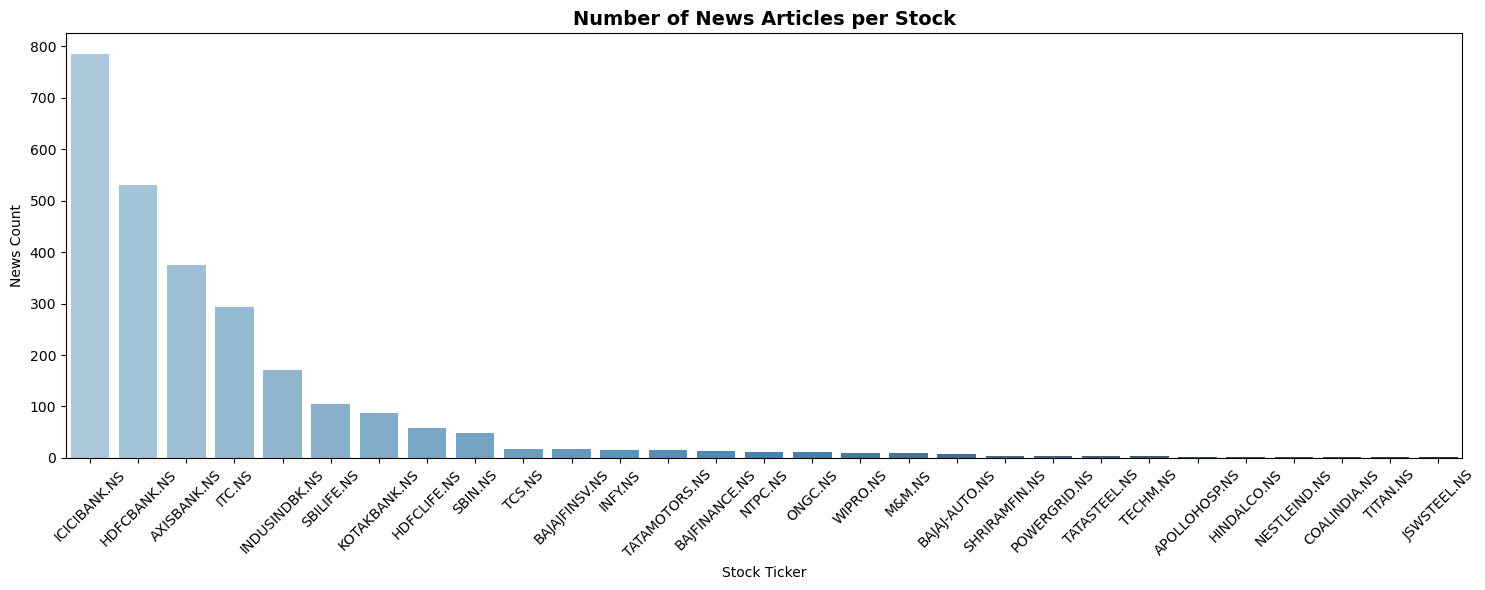

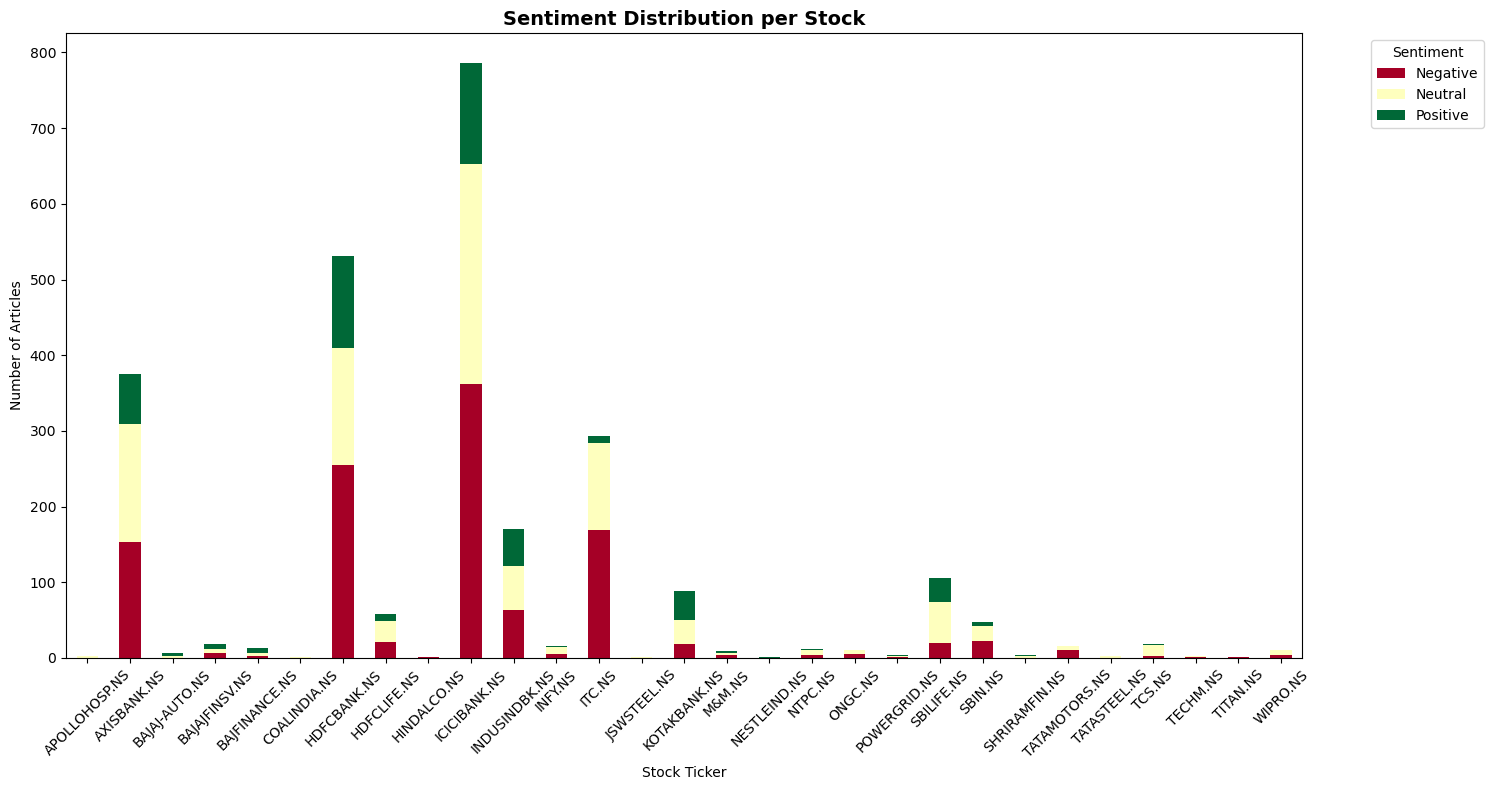

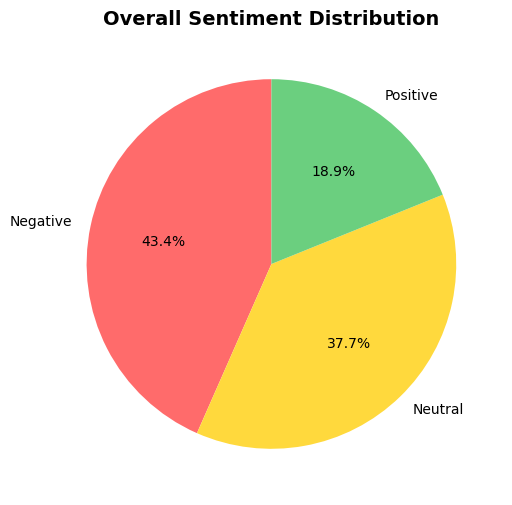


5. Loading stock price data...
Loading data for 29 stocks from 2003-02-12 to 2020-05-21


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********


6. Merging sentiment and stock data...


MergeError: Not allowed to merge between different levels. (2 levels on the left, 1 on the right)

In [10]:

# ================================================================================
# EXAMPLE USAGE
# ================================================================================

if __name__ == "__main__":
    # Option 1: Run full pipeline with model training
    featured_data, splits, model_manager = main_pipeline(
         model_choice="finbert-tone", 
         retrain_model=True
     )
    
    # Option 2: Compare different models
    # compare_finbert_models()
    
    # Option 3: Run with pre-trained model
    # featured_data, splits, model_manager = main_pipeline(
    #     model_choice="finbert-tone", 
    #     retrain_model=False
    # )
    
    print("Pipeline setup complete. Uncomment the desired execution option above.")

INDIAN STOCK SENTIMENT ANALYSIS & PREDICTION PIPELINE

1. Loading and preprocessing news data...
Loaded 50000 news articles
Filtered to 2606 articles for NIFTY 50 companies
Date range: 2003-02-12 00:00:00 to 2020-05-21 00:00:00

2. Initializing FinBERT model: finbert-tone
Loading trained model from: ./finbert-indian-sentiment

3. Analyzing sentiment...
Analyzing sentiment for all news articles...

4. Creating sentiment visualizations...


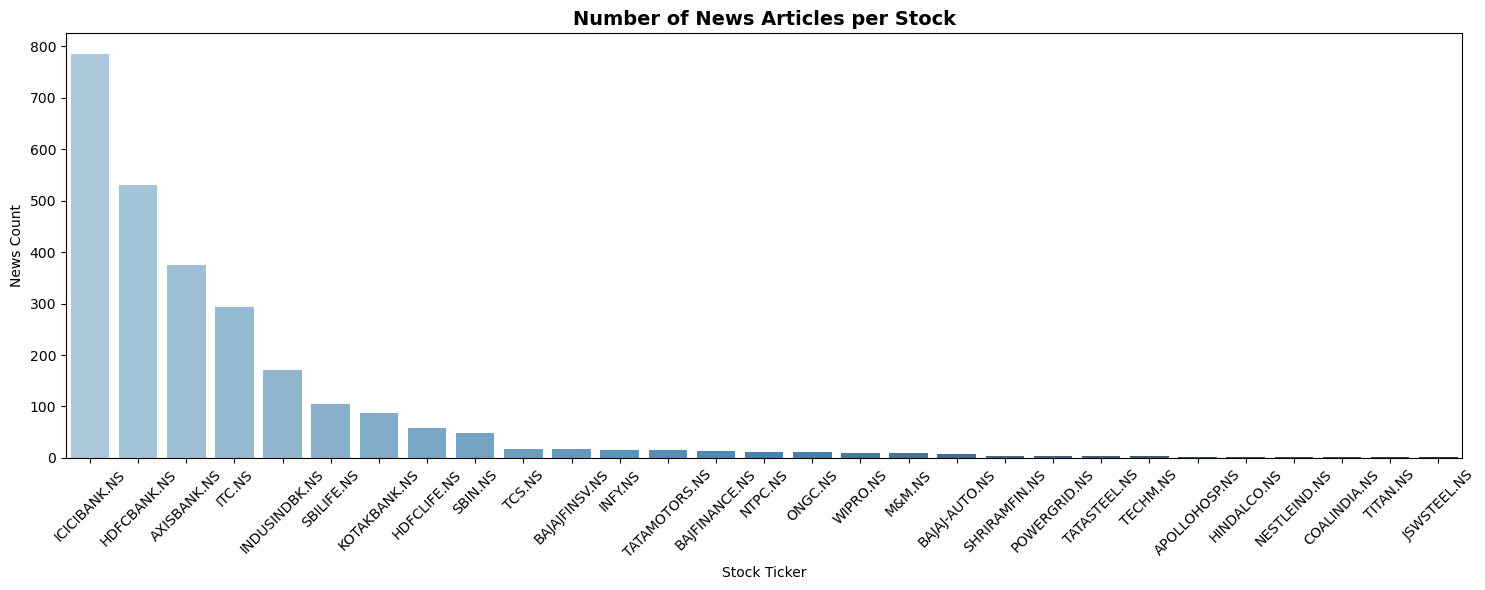

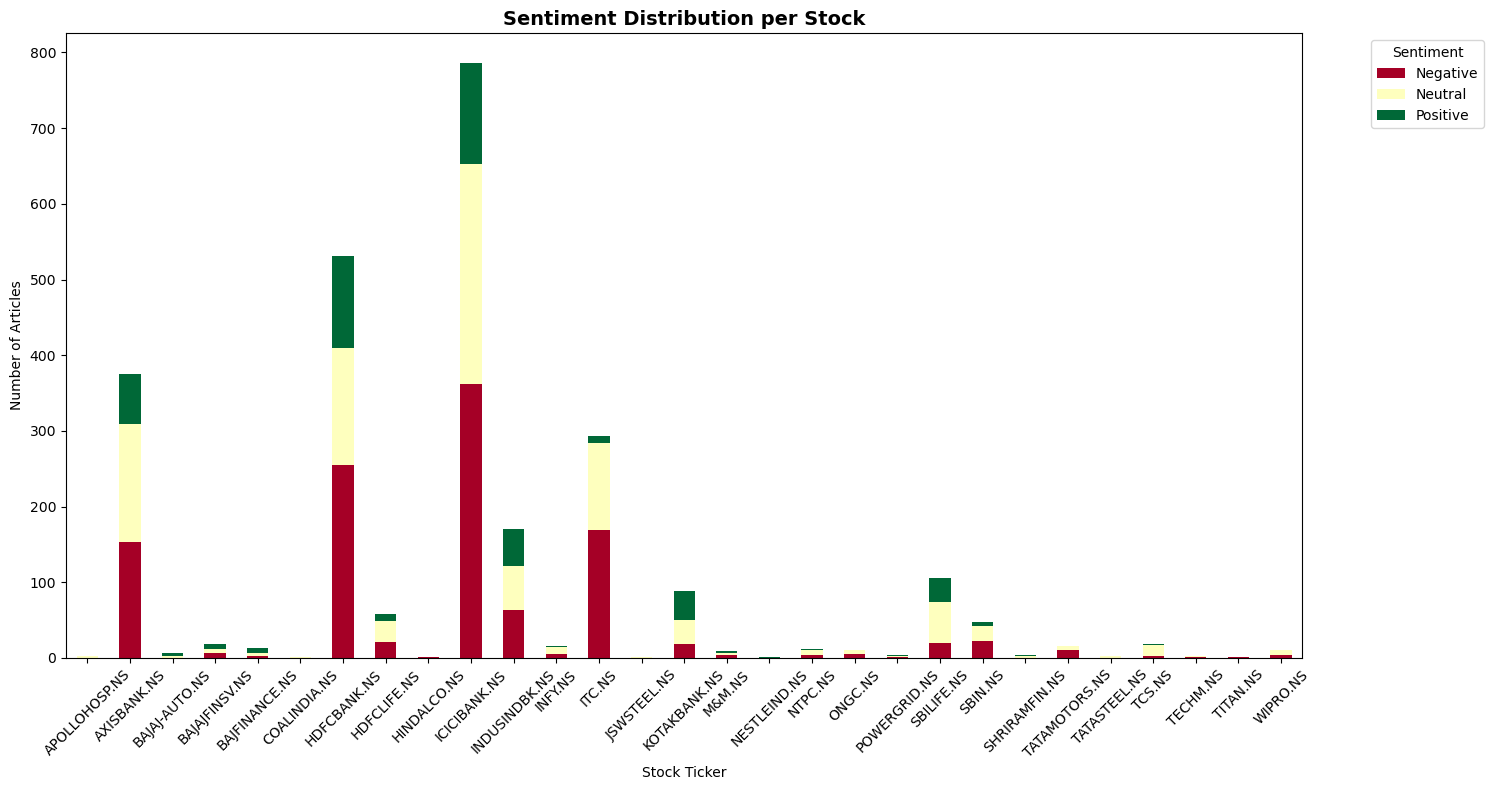

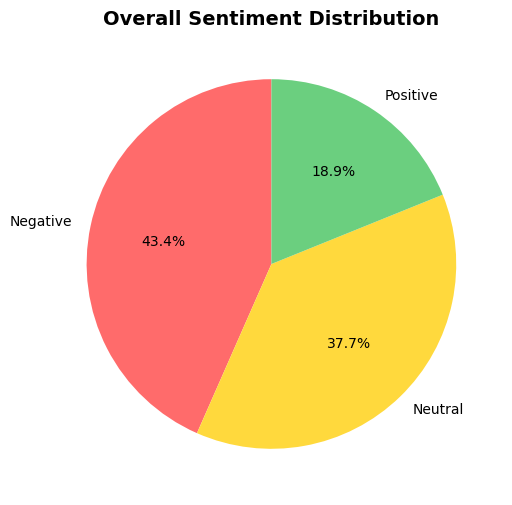


5. Loading stock price data...
Loading data for 29 stocks from 2003-02-12 to 2020-05-21
✅ Successfully loaded data for 29 stocks

6. Merging sentiment and stock data...

7. Creating technical indicators and features...

8. Creating time series splits...

Pipeline completed successfully!
Final dataset shape: (112334, 44)
Features created for 29 stocks
Processed data saved to: processed_stock_sentiment_data_finbert-tone.csv
Pipeline setup complete. Uncomment the desired execution option above.


In [14]:

# ================================================================================
# EXAMPLE USAGE After fine tuning
# ================================================================================

if __name__ == "__main__":
    # Option 1: Run full pipeline with model training
    featured_data, splits, model_manager = main_pipeline(
         model_choice="finbert-tone", 
         retrain_model=False
     )
    
    # Option 2: Compare different models
    # compare_finbert_models()
    
    # Option 3: Run with pre-trained model
    # featured_data, splits, model_manager = main_pipeline(
    #     model_choice="finbert-tone", 
    #     retrain_model=False
    # )
    
    print("Pipeline setup complete. Uncomment the desired execution option above.")

In [34]:
# ================================================================================
# 8. FIXED XGBOOST MODEL TRAINING AND SAVING
# ================================================================================

def train_and_save_xgboost_models(featured_data, data_splits, model_manager, 
                                 sequence_length=30, target_col='Price_Direction_1d',
                                 models_save_path="xgboost_models"):
    """
    Train and save XGBoost models for each ticker after FinBERT sentiment analysis
    """
    import os
    import pickle
    import xgboost as xgb
    from sklearn.metrics import accuracy_score, classification_report, f1_score
    import numpy as np
    
    # Create models directory
    os.makedirs(models_save_path, exist_ok=True)
    
    # Define feature columns (exclude metadata and future columns)
    feature_cols = [col for col in featured_data.columns if col not in 
                   ['Date', 'Ticker', target_col] and not col.startswith('Future_')]
    
    print(f"Training XGBoost models for {len(data_splits)} tickers...")
    print(f"Using {len(feature_cols)} features per timestep")
    print(f"Sequence length: {sequence_length}")
    
    # Results tracking
    model_results = {}
    
    for ticker_idx, (ticker, splits) in enumerate(data_splits.items(), 1):
        print(f"\n{'='*60}")
        print(f"Training model {ticker_idx}/{len(data_splits)}: {ticker}")
        print(f"{'='*60}")
        
        try:
            # Create sequences for this ticker
            train_sequences, train_targets = create_sequences_for_ticker(
                splits['train'], sequence_length, target_col, feature_cols
            )
            val_sequences, val_targets = create_sequences_for_ticker(
                splits['validation'], sequence_length, target_col, feature_cols
            )
            test_sequences, test_targets = create_sequences_for_ticker(
                splits['test'], sequence_length, target_col, feature_cols
            )
            
            # Check if we have enough data
            if len(train_sequences) < 10:
                print(f"⚠️  Insufficient training data for {ticker} ({len(train_sequences)} sequences). Skipping...")
                continue
            
            print(f"📊 Data shapes:")
            print(f"   Train: {train_sequences.shape[0]} sequences")
            print(f"   Validation: {val_sequences.shape[0]} sequences") 
            print(f"   Test: {test_sequences.shape[0]} sequences")
            
            # Flatten sequences for XGBoost (from 3D to 2D)
            X_train = train_sequences.reshape(train_sequences.shape[0], -1)
            X_val = val_sequences.reshape(val_sequences.shape[0], -1)
            X_test = test_sequences.reshape(test_sequences.shape[0], -1)
            
            print(f"   Flattened feature dimensions: {X_train.shape[1]}")
            
            # Initialize XGBoost model
            xgb_model = xgb.XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric='logloss',
                early_stopping_rounds=20,
                verbose=False
            )
            
            # Train model with validation set for early stopping
            print("🚀 Training XGBoost model...")
            xgb_model.fit(
                X_train, train_targets,
                eval_set=[(X_val, val_targets)],
                verbose=False
            )
            
            # Make predictions
            train_pred = xgb_model.predict(X_train)
            val_pred = xgb_model.predict(X_val)
            test_pred = xgb_model.predict(X_test)
            
            # Calculate metrics
            train_acc = accuracy_score(train_targets, train_pred)
            val_acc = accuracy_score(val_targets, val_pred)
            test_acc = accuracy_score(test_targets, test_pred)
            
            train_f1 = f1_score(train_targets, train_pred, average='weighted')
            val_f1 = f1_score(val_targets, val_pred, average='weighted')
            test_f1 = f1_score(test_targets, test_pred, average='weighted')
            
            print(f"📈 Model Performance:")
            print(f"   Train Accuracy: {train_acc:.4f} | F1: {train_f1:.4f}")
            print(f"   Val Accuracy:   {val_acc:.4f} | F1: {val_f1:.4f}")
            print(f"   Test Accuracy:  {test_acc:.4f} | F1: {test_f1:.4f}")
            
            # Detailed classification report for test set
            print(f"\n📋 Test Set Classification Report:")
            print(classification_report(test_targets, test_pred, 
                                      target_names=['DOWN', 'UP']))
            
            # Save model
            model_filename = f"{ticker.replace('.NS', '')}_xgboost_model.pkl"
            model_path = os.path.join(models_save_path, model_filename)
            
            with open(model_path, 'wb') as f:
                pickle.dump(xgb_model, f)
            
            print(f"💾 Model saved: {model_path}")
            
            # Store results
            model_results[ticker] = {
                'model_path': model_path,
                'train_accuracy': train_acc,
                'val_accuracy': val_acc,
                'test_accuracy': test_acc,
                'train_f1': train_f1,
                'val_f1': val_f1,
                'test_f1': test_f1,
                'train_samples': len(train_sequences),
                'val_samples': len(val_sequences),
                'test_samples': len(test_sequences),
                'feature_count': X_train.shape[1]
            }
            
        except Exception as e:
            print(f"❌ Error training model for {ticker}: {e}")
            continue
    
    # Print summary
    print(f"\n{'='*80}")
    print("🎯 XGBOOST TRAINING SUMMARY")
    print(f"{'='*80}")
    
    successful_models = len(model_results)
    print(f"✅ Successfully trained models: {successful_models}/{len(data_splits)}")
    
    if model_results:
        avg_test_acc = np.mean([r['test_accuracy'] for r in model_results.values()])
        avg_test_f1 = np.mean([r['test_f1'] for r in model_results.values()])
        print(f"📊 Average Test Accuracy: {avg_test_acc:.4f}")
        print(f"📊 Average Test F1 Score: {avg_test_f1:.4f}")
        
        # Top performing models
        sorted_models = sorted(model_results.items(), 
                             key=lambda x: x[1]['test_accuracy'], reverse=True)
        
        print(f"\n🏆 Top 5 Performing Models (Test Accuracy):")
        for i, (ticker, results) in enumerate(sorted_models[:5], 1):
            print(f"{i:2d}. {ticker:15s} - Accuracy: {results['test_accuracy']:.4f} | "
                  f"F1: {results['test_f1']:.4f}")
    
    # Save results summary
    results_summary = pd.DataFrame(model_results).T
    summary_path = os.path.join(models_save_path, "training_results_summary.csv")
    results_summary.to_csv(summary_path)
    print(f"\n📋 Results summary saved: {summary_path}")
    
    return model_results

# def create_sequences_for_ticker(data, sequence_length, target_col, feature_cols):
#     """
#     FIXED: Create sequences for a single ticker's data with proper date handling
#     """
#     # Make a copy and ensure proper date handling
#     data = data.copy()
    
#     # Ensure Date column is datetime
#     if 'Date' in data.columns:
#         data['Date'] = pd.to_datetime(data['Date'])
#         data = data.sort_values('Date').reset_index(drop=True)
    
#     sequences, targets = [], []
    
#     for i in range(sequence_length, len(data)):
#         # Check for data continuity (no major gaps)
#         date_range = data.iloc[i-sequence_length:i]['Date']
#         max_gap = (date_range.max() - date_range.min()).days
        
#         if max_gap <= sequence_length + 5:  # Allow for weekends/holidays
#             # Get sequence of features
#             sequence_data = data.iloc[i-sequence_length:i]
            
#             # Check if all required feature columns exist
#             missing_cols = [col for col in feature_cols if col not in sequence_data.columns]
#             if missing_cols:
#                 print(f"⚠️ Missing columns: {missing_cols}")
#                 continue
            
#             sequence = sequence_data[feature_cols].values
#             target = data.iloc[i][target_col]
            
#             # Only include if target is not NaN and sequence has no NaN
#             if not pd.isna(target) and not np.isnan(sequence).any():
#                 sequences.append(sequence)
#                 targets.append(int(target))
    
#     return np.array(sequences), np.array(targets)
# def create_sequences_for_ticker(data, sequence_length, target_col, feature_cols):
#     """Create sequences with detailed debugging"""
    
#     print(f"🔍 Creating sequences for ticker...")
#     print(f"   Input data shape: {data.shape}")
#     print(f"   Sequence length required: {sequence_length}")
#     print(f"   Target column: {target_col}")
#     print(f"   Feature columns count: {len(feature_cols)}")
    
#     # Make a copy and ensure proper date handling
#     data = data.copy()
    
#     if 'Date' in data.columns:
#         data['Date'] = pd.to_datetime(data['Date'])
#         data = data.sort_values('Date').reset_index(drop=True)
#         print(f"   Date range: {data['Date'].min()} to {data['Date'].max()}")
    
#     # Check if target column exists and has valid values
#     if target_col not in data.columns:
#         print(f"   ❌ Target column '{target_col}' not found!")
#         return np.array([]), np.array([])
    
#     valid_targets = data[target_col].notna().sum()
#     print(f"   Valid target values: {valid_targets}/{len(data)}")
    
#     # Check for missing feature columns
#     missing_features = [col for col in feature_cols if col not in data.columns]
#     if missing_features:
#         print(f"   ❌ Missing feature columns: {missing_features[:5]}...")  # Show first 5
#         return np.array([]), np.array([])
    
#     sequences, targets = [], []
    
#     for i in range(sequence_length, len(data)):
#         # Check for data continuity
#         date_range = data.iloc[i-sequence_length:i]['Date']
#         max_gap = (date_range.max() - date_range.min()).days
        
#         if max_gap <= sequence_length + 5:
#             sequence_data = data.iloc[i-sequence_length:i]
#             sequence = sequence_data[feature_cols].values
#             target = data.iloc[i][target_col]
            
#             if not pd.isna(target) and not np.isnan(sequence).any():
#                 sequences.append(sequence)
#                 targets.append(int(target))
    
#     print(f"   ✅ Created {len(sequences)} valid sequences")
#     return np.array(sequences), np.array(targets)
# def create_sequences_for_ticker(data, sequence_length, target_col, feature_cols):
#     """Fixed version with NaN handling"""
    
#     data = data.copy()
#     if 'Date' in data.columns:
#         data['Date'] = pd.to_datetime(data['Date'])
#         data = data.sort_values('Date').reset_index(drop=True)
    
#     # 🔧 FIX 1: Fill NaN values in feature columns
#     # Forward fill first, then backward fill, then fill remaining with 0
#     data[feature_cols] = data[feature_cols].fillna(method='ffill').fillna(method='bfill').fillna(0)
    
#     # 🔧 FIX 2: Remove rows where target is NaN
#     data = data.dropna(subset=[target_col]).reset_index(drop=True)
    
#     sequences, targets = [], []
    
#     for i in range(sequence_length, len(data)):
#         date_range = data.iloc[i-sequence_length:i]['Date']
#         max_gap = (date_range.max() - date_range.min()).days
        
#         if max_gap <= sequence_length + 5:
#             sequence_data = data.iloc[i-sequence_length:i]
#             sequence = sequence_data[feature_cols].values
#             target = data.iloc[i][target_col]
            
#             # Should not have NaN now, but double-check
#             if not pd.isna(target) and not np.isnan(sequence).any():
#                 sequences.append(sequence)
#                 targets.append(int(target))
    
#     return np.array(sequences), np.array(targets)
# def create_sequences_for_ticker_enhanced_debug(data, sequence_length, target_col, feature_cols):
#     """Enhanced debugging version to identify exact issues"""
    
#     print(f"🔍 ENHANCED DEBUGGING")
#     print(f"   Data shape: {data.shape}")
#     print(f"   Sequence length: {sequence_length}")
    
#     data = data.copy()
#     if 'Date' in data.columns:
#         data['Date'] = pd.to_datetime(data['Date'])
#         data = data.sort_values('Date').reset_index(drop=True)
    
#     # Check for NaN values in feature columns
#     print(f"\n📊 Feature Column NaN Analysis:")
#     for col in feature_cols[:10]:  # Check first 10 feature columns
#         nan_count = data[col].isna().sum()
#         total_count = len(data)
#         nan_pct = (nan_count / total_count) * 100
#         print(f"   {col}: {nan_count}/{total_count} ({nan_pct:.1f}% NaN)")
    
#     # Check target column
#     target_nans = data[target_col].isna().sum()
#     print(f"\n🎯 Target column '{target_col}': {target_nans}/{len(data)} NaN values")
    
#     sequences, targets = [], []
#     issues_breakdown = {
#         'target_nan': 0,
#         'missing_features': 0,
#         'sequence_nan': 0,
#         'date_gap': 0,
#         'success': 0
#     }
    
#     print(f"\n🔄 Processing sequences (showing first 5 issues):")
    
#     for i in range(sequence_length, min(len(data), sequence_length + 20)):  # Test first 20 potential sequences
        
#         # Get sequence data
#         seq_data = data.iloc[i-sequence_length:i]
#         target = data.iloc[i][target_col]
        
#         # Check target
#         if pd.isna(target):
#             issues_breakdown['target_nan'] += 1
#             if issues_breakdown['target_nan'] <= 5:
#                 print(f"   Row {i}: Target is NaN")
#             continue
        
#         # Check missing features
#         missing_cols = [col for col in feature_cols if col not in seq_data.columns]
#         if missing_cols:
#             issues_breakdown['missing_features'] += 1
#             if issues_breakdown['missing_features'] <= 5:
#                 print(f"   Row {i}: Missing columns: {missing_cols[:3]}...")
#             continue
        
#         # Check for NaN in sequence
#         sequence_values = seq_data[feature_cols].values
#         if np.isnan(sequence_values).any():
#             issues_breakdown['sequence_nan'] += 1
#             if issues_breakdown['sequence_nan'] <= 5:
#                 # Find which columns have NaN
#                 nan_cols = seq_data[feature_cols].columns[seq_data[feature_cols].isna().any()].tolist()
#                 print(f"   Row {i}: Sequence has NaN in columns: {nan_cols[:3]}...")
#             continue
        
#         # Check date gaps
#         date_range = seq_data['Date']
#         max_gap = (date_range.max() - date_range.min()).days
#         if max_gap > sequence_length + 5:
#             issues_breakdown['date_gap'] += 1
#             if issues_breakdown['date_gap'] <= 5:
#                 print(f"   Row {i}: Date gap too large: {max_gap} days")
#             continue
        
#         # Success
#         issues_breakdown['success'] += 1
#         sequences.append(sequence_values)
#         targets.append(int(target))
    
#     print(f"\n📋 Issues Summary:")
#     for issue, count in issues_breakdown.items():
#         print(f"   {issue}: {count}")
    
#     return np.array(sequences), np.array(targets), issues_breakdown

def create_sequences_for_ticker(data, sequence_length, target_col, feature_cols):
    """Fixed version that handles NaN and returns only 2 values"""
    
    data = data.copy()
    if 'Date' in data.columns:
        data['Date'] = pd.to_datetime(data['Date'])
        data = data.sort_values('Date').reset_index(drop=True)
    
    # **🔧 KEY FIX: Pre-filter out rows with NaN in feature columns**
    # This prevents NaN sequences from being created
    clean_data = data.dropna(subset=feature_cols).reset_index(drop=True)
    
    print(f"   Data after NaN filtering: {len(clean_data)}/{len(data)} rows")
    
    sequences, targets = [], []
    
    for i in range(sequence_length, len(clean_data)):
        # Check date continuity
        date_range = clean_data.iloc[i-sequence_length:i]['Date']
        max_gap = (date_range.max() - date_range.min()).days
        
        if max_gap <= sequence_length * 2 :
            sequence_data = clean_data.iloc[i-sequence_length:i]
            target = clean_data.iloc[i][target_col]
            
            # Double-check no NaN (should be clean now)
            if not pd.isna(target) and not sequence_data[feature_cols].isnull().any().any():
                sequences.append(sequence_data[feature_cols].values)
                targets.append(int(target))
    
    print(f"   ✅ Created {len(sequences)} valid sequences")
    return np.array(sequences), np.array(targets)



In [35]:
def create_sequences_for_ticker_deep_debug(data, sequence_length, target_col, feature_cols):
    """Deep debugging to find the exact issue"""
    
    data = data.copy()
    if 'Date' in data.columns:
        data['Date'] = pd.to_datetime(data['Date'])
        data = data.sort_values('Date').reset_index(drop=True)
    
    # Pre-filter NaN
    clean_data = data.dropna(subset=feature_cols).reset_index(drop=True)
    print(f"   Data after NaN filtering: {len(clean_data)}/{len(data)} rows")
    
    if len(clean_data) < sequence_length + 1:
        print(f"   ❌ Not enough data after filtering. Need {sequence_length + 1}, have {len(clean_data)}")
        return np.array([]), np.array([])
    
    # Check date gaps in detail
    print(f"   📅 Date analysis:")
    dates = clean_data['Date']
    date_gaps = dates.diff().dt.days
    large_gaps = date_gaps[date_gaps > 10]  # Gaps larger than 10 days
    print(f"   - Date range: {dates.min()} to {dates.max()}")
    print(f"   - Total days span: {(dates.max() - dates.min()).days}")
    print(f"   - Number of large gaps (>10 days): {len(large_gaps)}")
    if len(large_gaps) > 0:
        print(f"   - Largest gap: {large_gaps.max()} days")
    
    sequences, targets = [], []
    failed_reasons = {'date_gap': 0, 'target_nan': 0, 'other': 0}
    
    print(f"   🔄 Testing sequence creation (first 10 attempts):")
    
    for i in range(sequence_length, min(len(clean_data), sequence_length + 10)):
        # Get date range for this sequence
        seq_dates = clean_data.iloc[i-sequence_length:i]['Date']
        date_span = (seq_dates.max() - seq_dates.min()).days
        expected_span = sequence_length
        
        print(f"   Row {i}: Date span {date_span} days (expected ~{expected_span})")
        
        # Check date continuity
        if date_span > sequence_length + 5:
            failed_reasons['date_gap'] += 1
            print(f"     ❌ Date gap too large: {date_span} > {sequence_length + 5}")
            continue
        
        # Check target
        target = clean_data.iloc[i][target_col]
        if pd.isna(target):
            failed_reasons['target_nan'] += 1
            print(f"     ❌ Target is NaN")
            continue
        
        # Check sequence data
        sequence_data = clean_data.iloc[i-sequence_length:i]
        if sequence_data[feature_cols].isnull().any().any():
            failed_reasons['other'] += 1
            print(f"     ❌ Sequence still has NaN")
            continue
        
        print(f"     ✅ Valid sequence created")
        sequences.append(sequence_data[feature_cols].values)
        targets.append(int(target))
    
    print(f"   📋 Failure reasons: {failed_reasons}")
    print(f"   ✅ Total valid sequences: {len(sequences)}")
    
    return np.array(sequences), np.array(targets)


In [38]:

# ================================================================================
# 9. FIXED MAIN PIPELINE WITH XGBOOST TRAINING
# ================================================================================

def main_pipeline_with_xgboost(model_choice="finbert-tone", retrain_finbert=True, 
                              train_xgboost=True, sequence_length=30):
    """
    FIXED: Execute the complete pipeline including XGBoost model training
    """
    
    print("="*80)
    print("INDIAN STOCK SENTIMENT ANALYSIS & XGBOOST PREDICTION PIPELINE")
    print("="*80)
    
    # Steps 1-6: Same as before (data loading, FinBERT training, merging)
    news_df = preprocess_news_data()
    
    model_manager = FinBERTModelManager(model_choice)
    if retrain_finbert:
        model_manager.load_base_model()
        model_manager.fine_tune_model()
    else:
        model_manager.load_trained_model("./finbert-indian-sentiment")
    
    news_df = analyze_sentiment_with_model(news_df, model_manager)
    create_sentiment_visualizations(news_df)
    
    # Load stock data (with fixed stock loading)
    start_date = news_df['Date'].min().date()
    end_date = news_df['Date'].max().date()
    tickers = news_df['Ticker'].unique().tolist()
    
    stock_data = []
    for ticker in tickers:
        try:
            print(f"  Downloading {ticker}...")
            data = yf.download(ticker, start=start_date, end=end_date, progress=False)
            
            if not data.empty:
                data = data.reset_index()
                if isinstance(data.columns, pd.MultiIndex):
                    data.columns = data.columns.get_level_values(0)
                data['Ticker'] = ticker
                stock_data.append(data)
                
        except Exception as e:
            print(f"  ❌ Failed to download data for {ticker}: {e}")
    
    stock_df = pd.concat(stock_data, ignore_index=True)
    merged_data = align_sentiment_stock_data(news_df, stock_df)
    
    # Step 7: FIXED - Create features with proper error handling
    print("\n7. Creating technical indicators and features...")
    
    def safe_feature_creation(group_data):
        """Safely create features for each ticker group"""
        try:
            # Apply the fixed create_comprehensive_features function
            featured_group = create_comprehensive_features(group_data)
            # Apply target variable creation
            return create_target_variables(featured_group)
        except Exception as e:
            ticker = group_data['Ticker'].iloc[0] if 'Ticker' in group_data.columns else 'Unknown'
            print(f"⚠️ Error creating features for {ticker}: {e}")
            # Return original data if feature creation fails
            return group_data
    
    featured_data = merged_data.groupby('Ticker').apply(safe_feature_creation).reset_index(drop=True)
    
    print("\n8. Creating time series splits...")
    data_splits = create_time_series_splits(featured_data)
    
    # Step 9: Train XGBoost models
    if train_xgboost:
        print("\n9. Training XGBoost models for all tickers...")
        model_results = train_and_save_xgboost_models(
            featured_data, data_splits, model_manager, sequence_length=sequence_length
        )
        
        # Feature importance analysis
        print("\n10. Analyzing feature importance...")
        importance_df = create_feature_importance_analysis(
            model_results, featured_data, sequence_length=sequence_length
        )
        
        return featured_data, data_splits, model_manager, model_results, importance_df
    
    return featured_data, data_splits, model_manager

def create_feature_importance_analysis(model_results, featured_data, sequence_length=30):
    """
    FIXED: Analyze feature importance across all trained models
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pickle
    
    print("🔍 Analyzing feature importance across models...")
    
    # Get feature names
    feature_cols = [col for col in featured_data.columns if col not in 
                   ['Date', 'Ticker', 'Price_Direction_1d'] and not col.startswith('Future_')]
    
    # Create flattened feature names for sequences
    flattened_feature_names = []
    for day in range(sequence_length):
        for feature in feature_cols:
            flattened_feature_names.append(f"{feature}_day_{sequence_length-day}")
    
    # Collect feature importances from all models
    all_importances = []
    model_names = []
    
    for ticker, results in model_results.items():
        try:
            # Load model
            with open(results['model_path'], 'rb') as f:
                model = pickle.load(f)
            
            importances = model.feature_importances_
            all_importances.append(importances)
            model_names.append(ticker)
            
        except Exception as e:
            print(f"Error loading model for {ticker}: {e}")
            continue
    
    if not all_importances:
        print("No models loaded for feature importance analysis")
        return pd.DataFrame()
    
    # Calculate average importance across models
    avg_importance = np.mean(all_importances, axis=0)
    std_importance = np.std(all_importances, axis=0)
    
    # Create importance DataFrame
    importance_df = pd.DataFrame({
        'feature': flattened_feature_names[:len(avg_importance)],
        'avg_importance': avg_importance,
        'std_importance': std_importance
    }).sort_values('avg_importance', ascending=False)
    
    # Plot top features
    plt.figure(figsize=(15, 10))
    top_features = importance_df.head(20)
    
    plt.subplot(2, 1, 1)
    bars = plt.barh(range(len(top_features)), top_features['avg_importance'])
    plt.yticks(range(len(top_features)), top_features['feature'])
    plt.xlabel('Average Feature Importance')
    plt.title('Top 20 Most Important Features (Average Across All Models)')
    plt.gca().invert_yaxis()
    
    # Add error bars
    plt.errorbar(top_features['avg_importance'], range(len(top_features)), 
                xerr=top_features['std_importance'], fmt='none', color='red', alpha=0.5)
    
    # Feature category analysis
    plt.subplot(2, 1, 2)
    
    # Group features by category
    sentiment_features = importance_df[importance_df['feature'].str.contains('avg_|news_|sentiment')]
    technical_features = importance_df[importance_df['feature'].str.contains('SMA_|EMA_|RSI|MACD|BB_')]
    price_features = importance_df[importance_df['feature'].str.contains('Open|High|Low|Close|Volume')]
    
    categories = ['Sentiment', 'Technical', 'Price', 'Other']
    category_importance = [
        sentiment_features['avg_importance'].sum(),
        technical_features['avg_importance'].sum(), 
        price_features['avg_importance'].sum(),
        importance_df['avg_importance'].sum() - sentiment_features['avg_importance'].sum() - 
        technical_features['avg_importance'].sum() - price_features['avg_importance'].sum()
    ]
    
    plt.pie(category_importance, labels=categories, autopct='%1.1f%%', startangle=90)
    plt.title('Feature Importance by Category')
    
    plt.tight_layout()
    plt.show()
    
    # Save importance analysis
    importance_df.to_csv('feature_importance_analysis.csv', index=False)
    print("📊 Feature importance analysis saved to 'feature_importance_analysis.csv'")
    
    return importance_df

INDIAN STOCK SENTIMENT ANALYSIS & XGBOOST PREDICTION PIPELINE
Loaded 50000 news articles
Filtered to 2606 articles for NIFTY 50 companies
Date range: 2003-02-12 00:00:00 to 2020-05-21 00:00:00
Loading trained model from: ./finbert-indian-sentiment
Analyzing sentiment for all news articles...


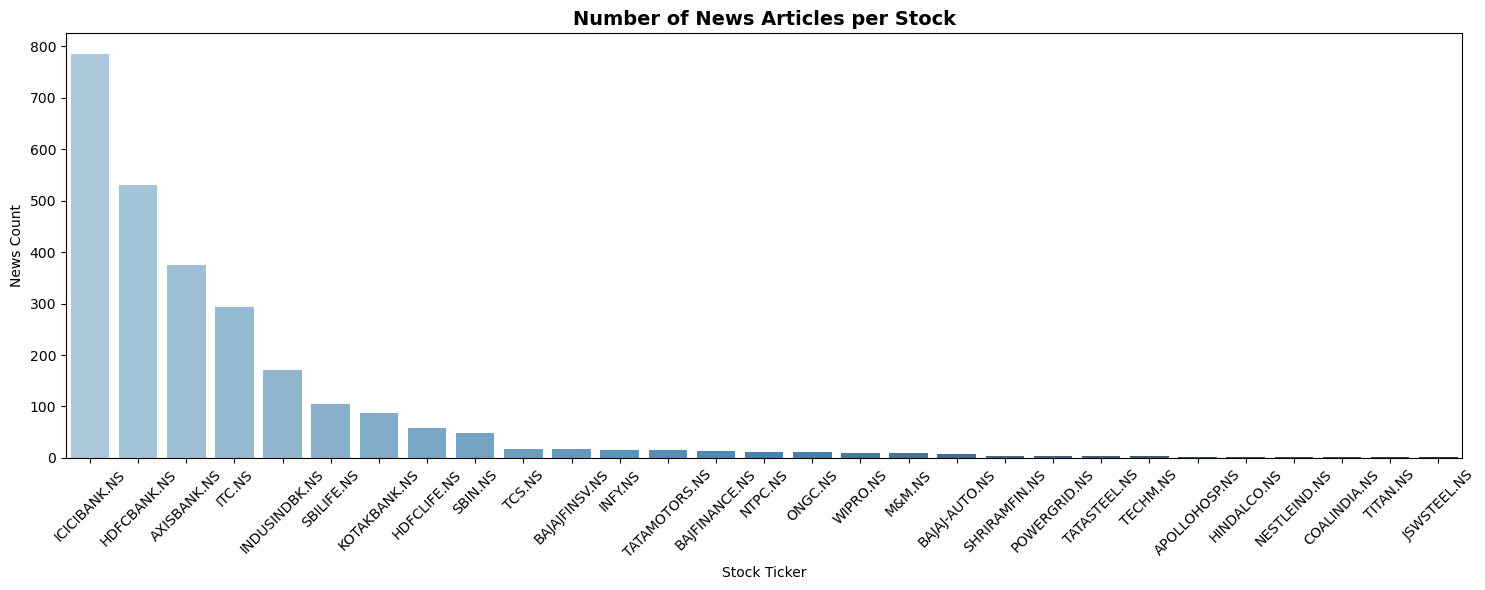

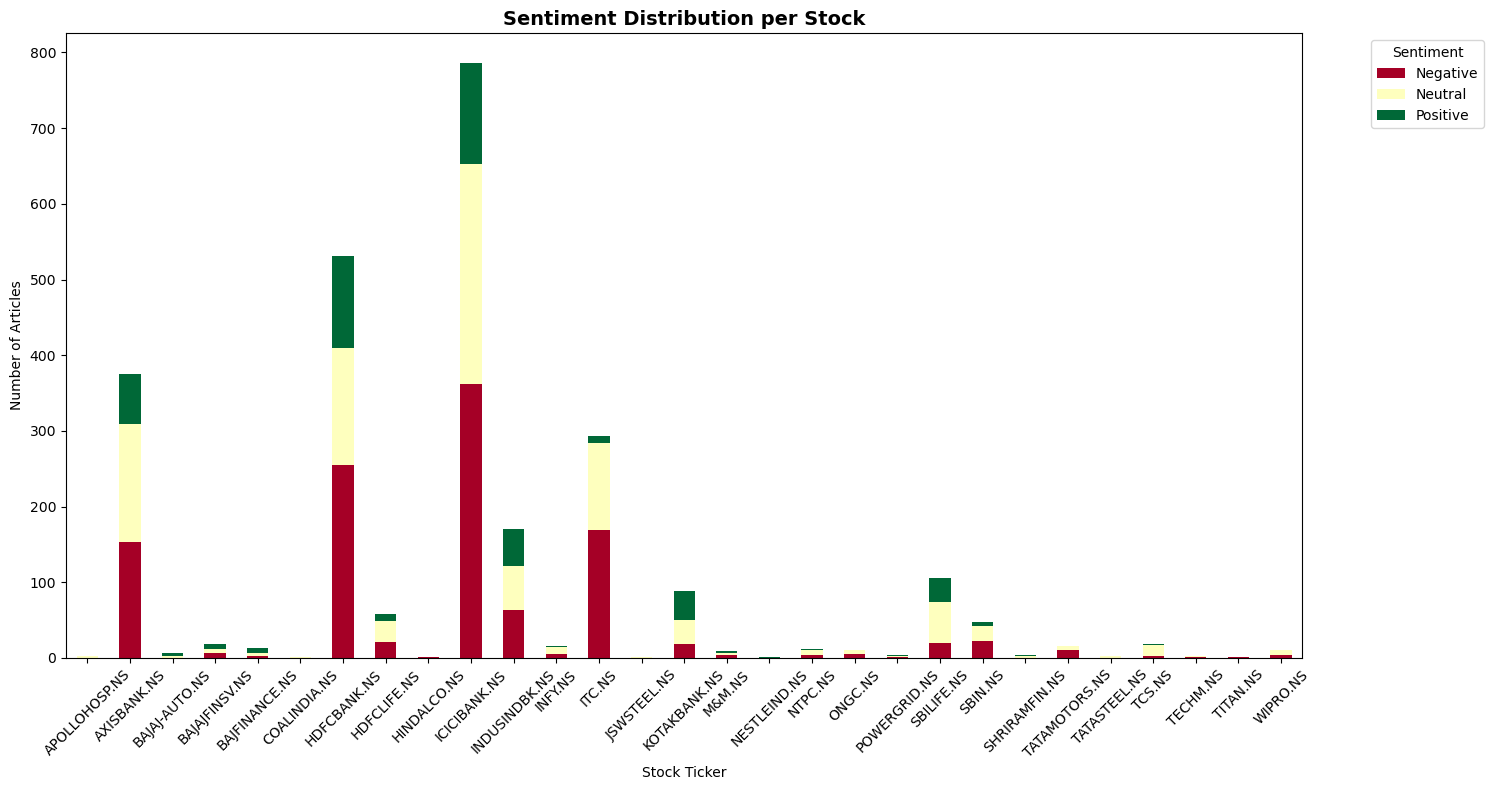

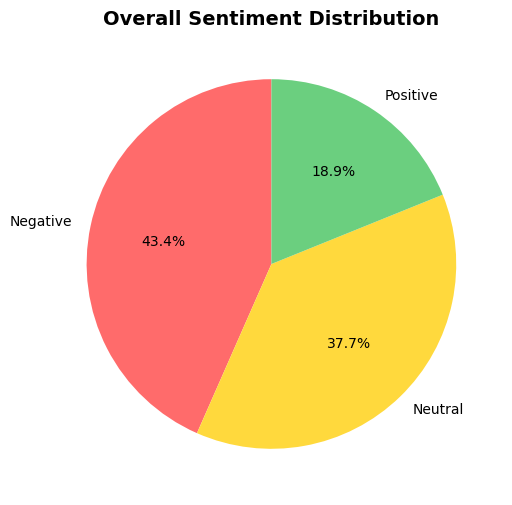


7. Creating technical indicators and features...

8. Creating time series splits...

9. Training XGBoost models for all tickers...
Training XGBoost models for 29 tickers...
Using 37 features per timestep
Sequence length: 30

Training model 1/29: APOLLOHOSP.NS
   Data after NaN filtering: 3027/3081 rows
   ✅ Created 2997 valid sequences
   Data after NaN filtering: 343/343 rows
   ✅ Created 313 valid sequences
   Data after NaN filtering: 856/856 rows
   ✅ Created 826 valid sequences
📊 Data shapes:
   Train: 2997 sequences
   Validation: 313 sequences
   Test: 826 sequences
   Flattened feature dimensions: 1110
🚀 Training XGBoost model...
📈 Model Performance:
   Train Accuracy: 0.9930 | F1: 0.9930
   Val Accuracy:   0.7348 | F1: 0.7348
   Test Accuracy:  0.7349 | F1: 0.7343

📋 Test Set Classification Report:
              precision    recall  f1-score   support

        DOWN       0.73      0.77      0.75       430
          UP       0.74      0.69      0.71       396

    accuracy    

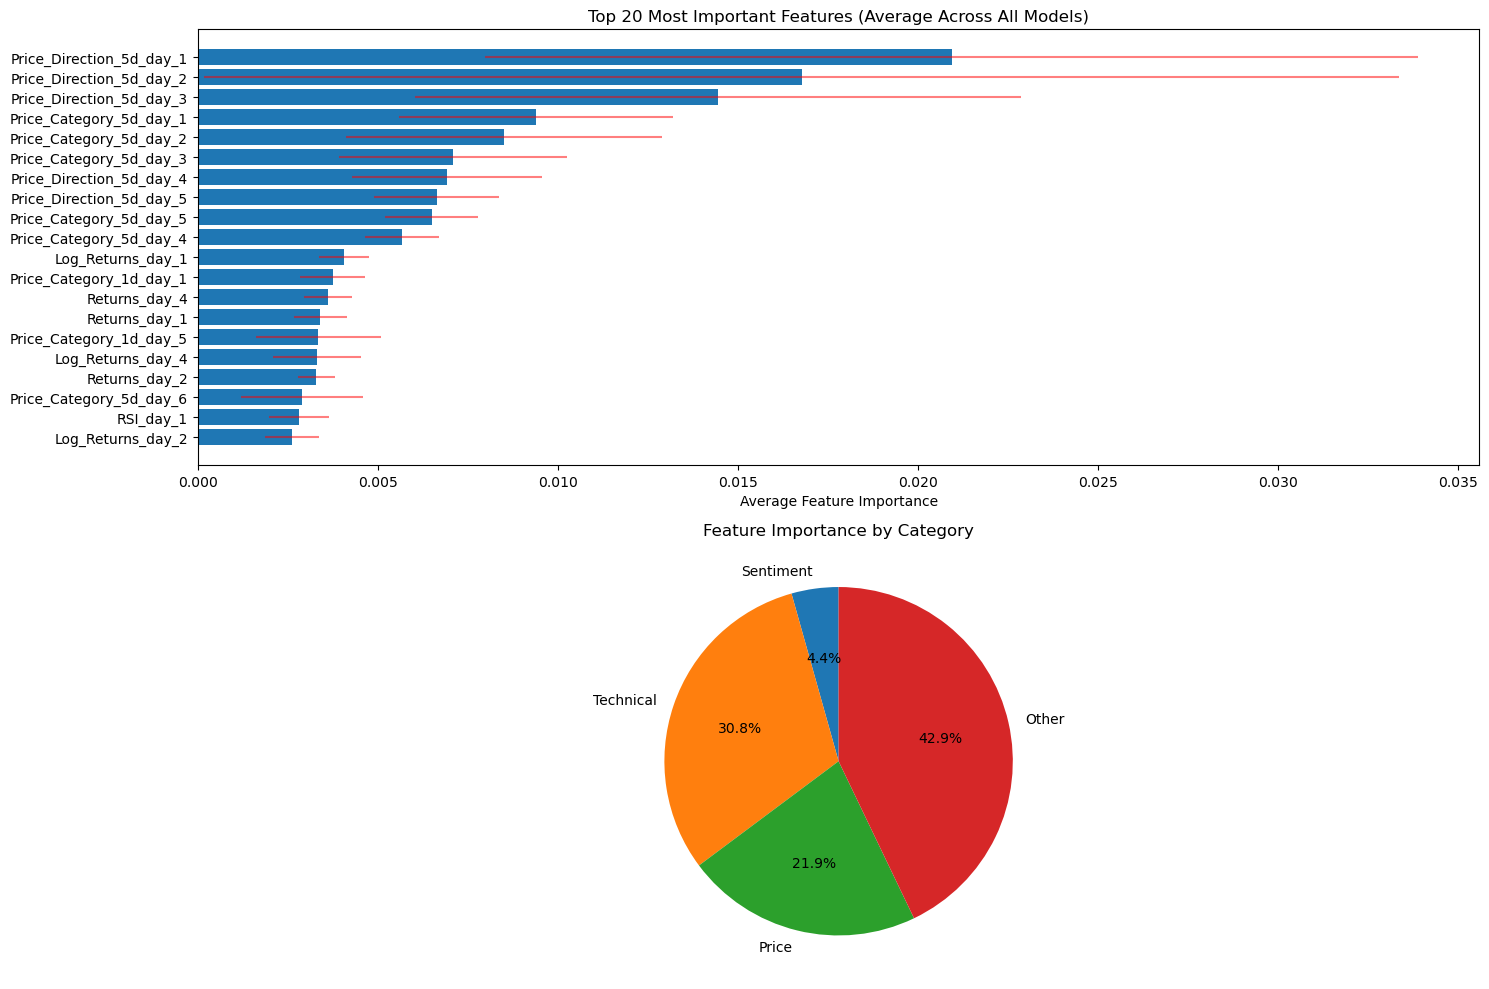

📊 Feature importance analysis saved to 'feature_importance_analysis.csv'

✅ Pipeline completed successfully!
   - Trained 29 XGBoost models
   - Models saved in 'xgboost_models/' directory
   - Feature importance analysis completed


In [40]:

# ================================================================================
# EXAMPLE USAGE
# ================================================================================

if __name__ == "__main__":
    # Run complete pipeline with XGBoost training
    results = main_pipeline_with_xgboost(
        model_choice="finbert-tone",
        retrain_finbert=False,  # Set to True if you want to retrain FinBERT
        train_xgboost=True,     # Set to True to train XGBoost models
        sequence_length=30
    )
    
    if len(results) == 5:
        featured_data, data_splits, model_manager, model_results, importance_df = results
        print(f"\n✅ Pipeline completed successfully!")
        print(f"   - Trained {len(model_results)} XGBoost models")
        print(f"   - Models saved in 'xgboost_models/' directory")
        print(f"   - Feature importance analysis completed")
    else:
        featured_data, data_splits, model_manager = results
        print(f"\n✅ Pipeline completed (without XGBoost training)")


In [6]:
from GoogleNews import GoogleNews
days=10
gnews = GoogleNews(lang="en", period=f"{days}d")
gnews.search("Reliance " + " Company News")

HTTP Error 429: Too Many Requests
